In [1]:
import numpy as np
import sympy as sm
import pandas as pd

import scipy as sp
from scipy.integrate import solve_ivp
import scipy.optimize as optimize

import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns

import os
from tqdm import tqdm
import glob

In [2]:
def dydt(t, y, par):

    par = np.abs(par)

    alpha = par[0]
    beta  = par[1]

    S = y[0]
    I = y[1]
    R = y[2]
    C = y[3]

    dS =  -beta*S*I
    dI = beta*S*I - alpha*I
    dR = alpha*I
    dC = beta*S*I

    return np.array([dS,dI,dR,dC])

# Solve the ODE model using solve_ivp


def SolveModel(par,tspan,init_cond,t_eval):

    ode_soln = solve_ivp(dydt,
                         tspan,
                         init_cond,
                         t_eval = t_eval,
                         args = (par,))
    return ode_soln

In [3]:
# Define initial conditions
N0 = 1000
I0 = 5
R0 = 0
C0 = 0
S0 = N0 - I0 - R0
init_cond = np.array([S0, I0, R0, C0])

#Define time variables
t_final=100
tspan = (1,t_final)
t_eval = np.arange(1, 101)
tdata = np.arange(0,t_final)

In [4]:
params_df = pd.read_csv('../data/params_combos.csv')

In [5]:
params_df["R0"] = (params_df["Beta"] * 1000 / params_df["Alpha"]).round(2) #Calculate R0
params_df = params_df.sort_values("R0").reset_index(drop=True) #Sort df by R0

# Load trajectory files and map to params_df
data_dir = '../data/ctmc_trajectories' #Load data
csv_files = sorted(glob.glob(os.path.join(data_dir, '*.csv')))
param_to_file = {}
for file in csv_files:
    name = os.path.basename(file).replace('.csv', '').replace("alpha", "").replace("beta", "")
    parts = name.split("_")
    alpha = float(parts[0].replace("p", "."))
    beta = float(parts[1].replace("p", "."))
    param_to_file[(alpha, beta)] = file

In [6]:
!pip install tslearn


Defaulting to user installation because normal site-packages is not writeable


## DTW registration method

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


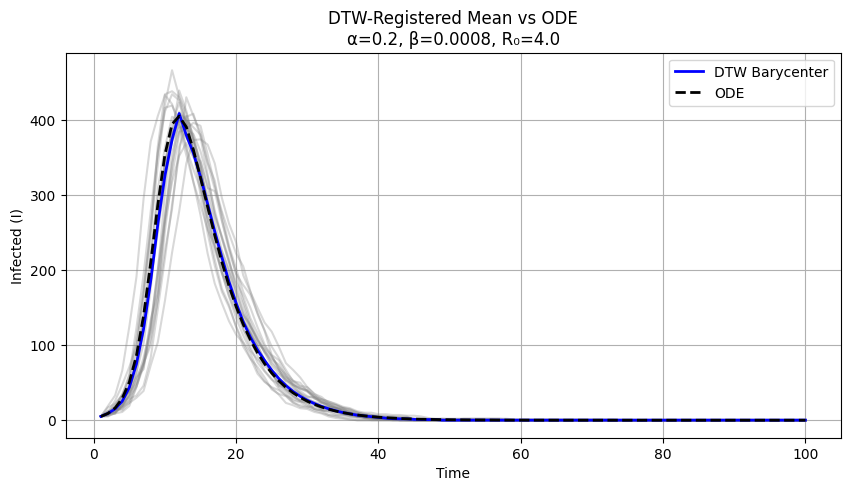

In [7]:
from tslearn.barycenters import dtw_barycenter_averaging
from tslearn.preprocessing import TimeSeriesResampler
from tslearn.utils import to_time_series_dataset

# Select one param set
combo_index = 5
row = params_df.iloc[combo_index]
alpha, beta = row["Alpha"], row["Beta"]
par = (alpha, beta)

# Solve ODE
sol = SolveModel(par, tspan, init_cond, t_eval)
I_ode = sol.y[1]

# Load CTMC data
df = pd.read_csv(param_to_file[par])

# Select N trajectories and resample to fixed length
N = 1000  # number of CTMC curves to register
traj_ids = df["trajectory"].unique()[:N]
ctmc_curves = []

for traj_id in traj_ids:
    df_traj = df[df["trajectory"] == traj_id]
    I = np.interp(t_eval, df_traj["time"], df_traj["I"])  # ensure same time base
    ctmc_curves.append(I)

ctmc_dataset = to_time_series_dataset(ctmc_curves)  # shape: (N, T, 1)
ctmc_dataset = ctmc_dataset.squeeze()  # shape: (N, T)

# Compute DTW barycenter
dtw_mean = dtw_barycenter_averaging(ctmc_dataset)

# Plot result
plt.figure(figsize=(10, 5))
for i in range(min(20, N)):
    plt.plot(t_eval, ctmc_dataset[i], alpha=0.3, color="gray")
plt.plot(t_eval, dtw_mean, label="DTW Barycenter", color="blue", linewidth=2)
plt.plot(t_eval, I_ode, label="ODE", color="black", linestyle="--", linewidth=2)
plt.legend()
plt.title(f"DTW-Registered Mean vs ODE\nα={alpha}, β={beta}, R₀={row['R0']}")
plt.xlabel("Time")
plt.ylabel("Infected (I)")
plt.grid(True)
plt.show()


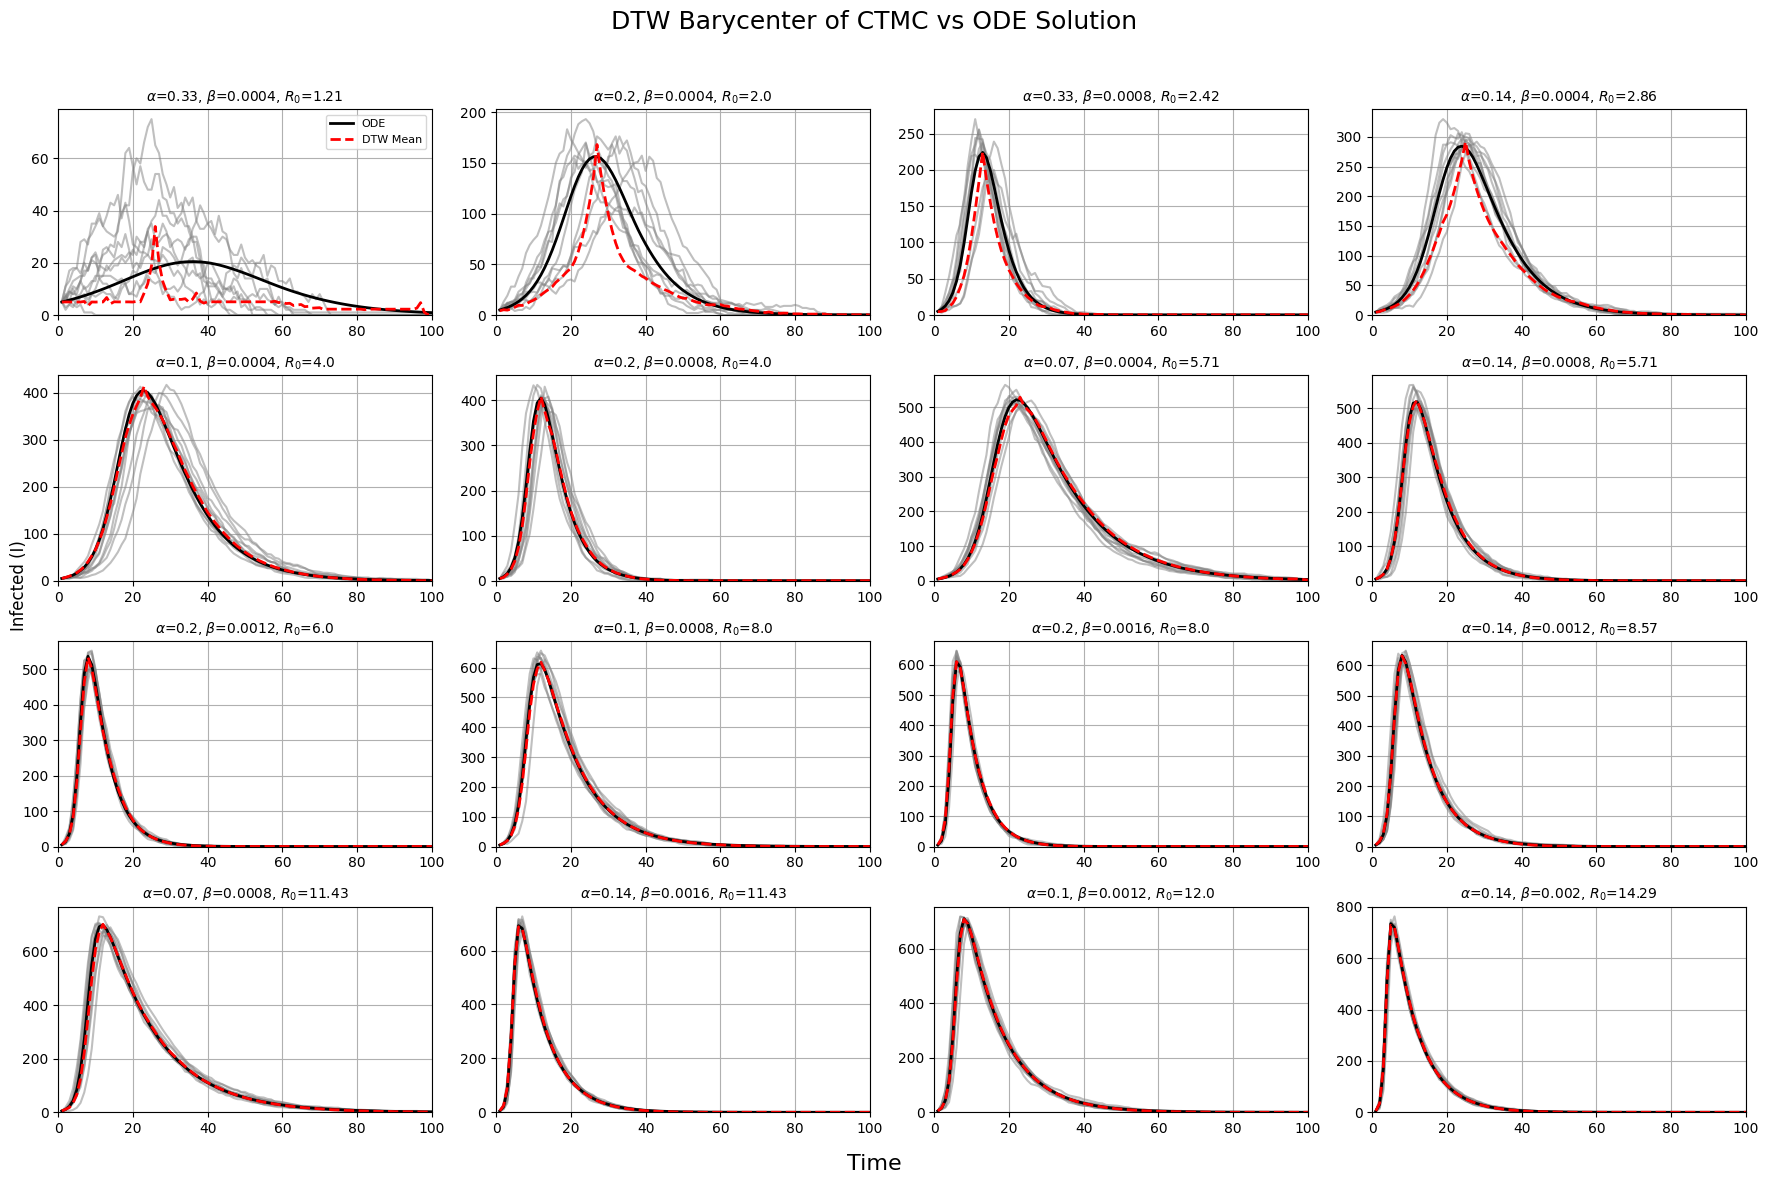

In [8]:
# Prep plot
num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))
fig, ax = plt.subplots(num_rows, num_cols, figsize=(18, 12))
ax = ax.flatten()

# Sort combos by R0
sorted_params = params_df.sort_values("R0").reset_index(drop=True)

# Process each combo
for idx, row in sorted_params.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    par = (alpha, beta)
    file = param_to_file.get(par)

    if file is None or not os.path.exists(file):
        ax[idx].text(0.5, 0.5, "Missing file", ha="center", va="center", transform=ax[idx].transAxes)
        continue

    df = pd.read_csv(file)
    traj_ids = df["trajectory"].unique()[:500]  # pick 50 CTMC runs
    ctmc_curves = []

    for traj_id in traj_ids:
        df_traj = df[df["trajectory"] == traj_id]
        I = np.interp(t_eval, df_traj["time"], df_traj["I"])
        ctmc_curves.append(I)

    ctmc_dataset = to_time_series_dataset(ctmc_curves).squeeze()  # shape (N, T)

    # DTW mean
    dtw_mean = dtw_barycenter_averaging(ctmc_dataset)

    # ODE
    sol = SolveModel((alpha, beta), tspan, init_cond, t_eval)
    I_ode = sol.y[1]

    # Plot
    for i in range(min(10, len(ctmc_dataset))):
        ax[idx].plot(t_eval, ctmc_dataset[i], color="gray", alpha=0.5)

    ax[idx].plot(t_eval, I_ode, color="black", linewidth=2, label="ODE")
    ax[idx].plot(t_eval, dtw_mean, color="red", linewidth=2, linestyle="--", label="DTW Mean")

    ax[idx].set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0}", fontsize=10)
    ax[idx].set_xlim([0, t_final])
    ax[idx].set_ylim(bottom=0)
    ax[idx].grid(True)

    if idx == 0:
        ax[idx].legend(fontsize=8)

# Clean up unused axes
for j in range(idx + 1, len(ax)):
    fig.delaxes(ax[j])

# Final layout
fig.suptitle("DTW Barycenter of CTMC vs ODE Solution", fontsize=18)
fig.supxlabel("Time", fontsize=16)
fig.supylabel("Infected (I)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## Extrapolate warping fuctions

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/scipy/interpolate/_interpolate.py:479: RuntimeWarning: divide by zero encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]
/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/scipy/interpolate/_interpolate.py:482: RuntimeWarning: invalid value encountered in multiply
  y_new = slope*(x_new - x_lo)[:, None] + y_lo


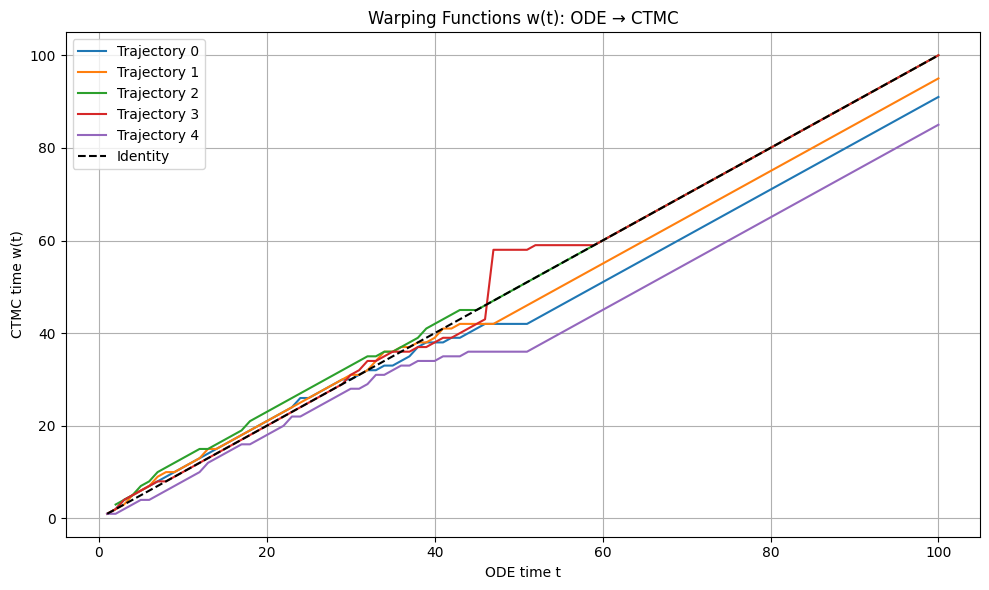

In [9]:
from tslearn.metrics import dtw_path
from scipy.interpolate import interp1d

# Select parameter set
combo_index = 5
row = params_df.iloc[combo_index]
alpha, beta = row["Alpha"], row["Beta"]
par = (alpha, beta)

# ODE curve
sol = SolveModel(par, tspan, init_cond, t_eval)
I_ode = sol.y[1]

# Load CTMC data
df = pd.read_csv(param_to_file[par])
traj_ids = df["trajectory"].unique()[:5]  # use 5 trajectories to visualize

plt.figure(figsize=(10, 6))

for traj_id in traj_ids:
    df_traj = df[df["trajectory"] == traj_id]
    I_ctmc = np.interp(t_eval, df_traj["time"], df_traj["I"])

    # Compute DTW alignment path
    path, _ = dtw_path(I_ode, I_ctmc)

    # Extract warping function w(t): for each i in ODE, what j in CTMC was matched?
    t_ref = []
    t_warp = []
    for i, j in path:
        t_ref.append(t_eval[i])
        t_warp.append(t_eval[j])

    # Sort and interpolate to get a smooth w(t)
    sorted_pairs = sorted(zip(t_ref, t_warp))
    t_ref_sorted, t_warp_sorted = zip(*sorted_pairs)
    w_interp = interp1d(t_ref_sorted, t_warp_sorted, bounds_error=False, fill_value="extrapolate")

    # Plot warping function
    plt.plot(t_eval, w_interp(t_eval), label=f"Trajectory {traj_id}")

plt.plot(t_eval, t_eval, color="black", linestyle="--", label="Identity")
plt.title("Warping Functions w(t): ODE → CTMC")
plt.xlabel("ODE time t")
plt.ylabel("CTMC time w(t)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


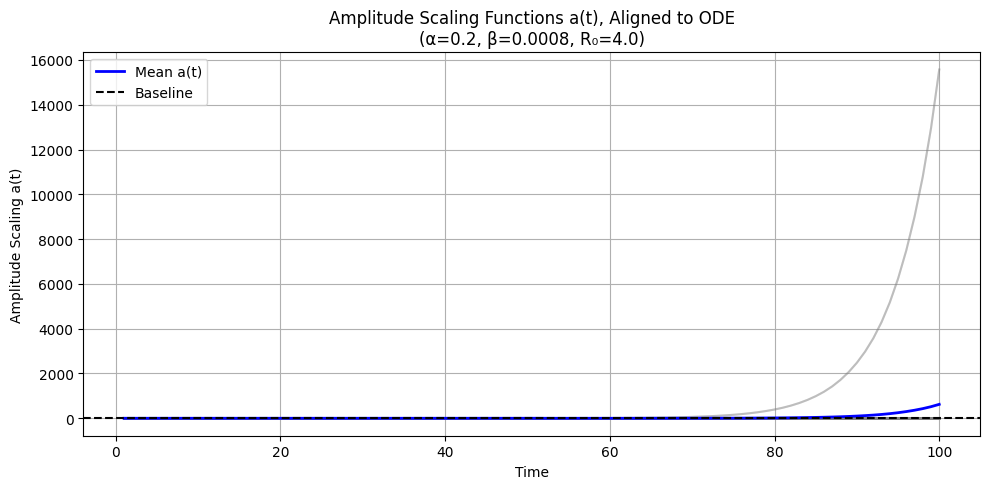

In [10]:
from tslearn.metrics import dtw_path
from scipy.interpolate import interp1d
import numpy as np
import matplotlib.pyplot as plt

# Select parameter set
combo_index = 5  # change as needed
row = params_df.iloc[combo_index]
alpha, beta = row["Alpha"], row["Beta"]
par = (alpha, beta)

# Solve ODE
sol = SolveModel(par, tspan, init_cond, t_eval)
I_ode = sol.y[1]

# Load CTMC data
df = pd.read_csv(param_to_file[par])
traj_ids = df["trajectory"].unique()[:50]  # number of trajectories to process

# Store amplitude functions
a_matrix = []

for traj_id in traj_ids:
    df_traj = df[df["trajectory"] == traj_id]
    I_ctmc = np.interp(t_eval, df_traj["time"], df_traj["I"])

    # DTW alignment
    path, _ = dtw_path(I_ode, I_ctmc)

    # Build warped CTMC aligned to ODE time
    I_ctmc_warped = np.zeros_like(I_ode)
    counts = np.zeros_like(I_ode)

    for i, j in path:
        I_ctmc_warped[i] += I_ctmc[j]
        counts[i] += 1

    counts[counts == 0] = 1
    I_ctmc_warped /= counts

    # Estimate amplitude scaling function a(t)
    with np.errstate(divide='ignore', invalid='ignore'):
        a_t = np.where(I_ode > 1e-6, I_ctmc_warped / I_ode, np.nan)

    a_matrix.append(a_t)

a_matrix = np.array(a_matrix)  # shape: (n_traj, T)
mean_a = np.nanmean(a_matrix, axis=0)

# Plot
plt.figure(figsize=(10, 5))
for i in range(len(a_matrix)):
    plt.plot(t_eval, a_matrix[i], color="gray", alpha=0.3)
plt.plot(t_eval, mean_a, color="blue", linewidth=2, label="Mean a(t)")
plt.axhline(1.0, color="black", linestyle="--", label="Baseline")
plt.title(f"Amplitude Scaling Functions a(t), Aligned to ODE\n(α={alpha}, β={beta}, R₀={row['R0']})")
plt.xlabel("Time")
plt.ylabel("Amplitude Scaling a(t)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Simulate data using warping and amplitude scaling fuctions

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/scipy/interpolate/_interpolate.py:479: RuntimeWarning: divide by zero encountered in divide
  slope = (y_hi - y_lo) / (x_hi - x_lo)[:, None]
/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/scipy/interpolate/_interpolate.py:482: RuntimeWarning: invalid value encountered in multiply
  y_new = slope*(x_new - x_lo)[:, None] + y_lo


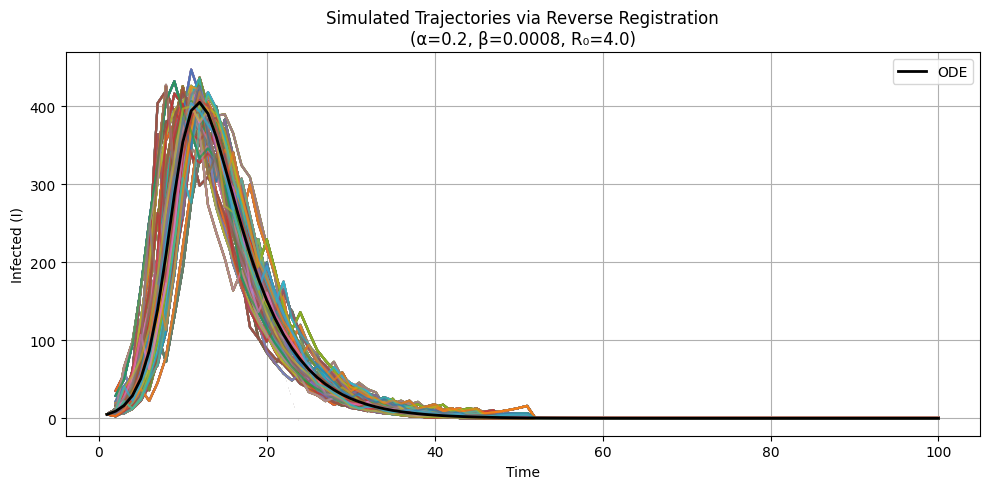

In [11]:
from scipy.interpolate import interp1d

# Number of synthetic trajectories
n_sims = 1000
simulated_curves = []

# Sample from precomputed warping paths and amplitude functions
for _ in range(n_sims):
    # Sample a trajectory index
    idx = np.random.choice(range(len(a_matrix)))
    a_t = a_matrix[idx]
    df_traj = df[df["trajectory"] == traj_ids[idx]]


    # Get a(t)
    a_t = a_matrix[idx]

    # Get DTW alignment path (reuse same CTMCs as used for a(t))
    df_traj = df[df["trajectory"] == traj_ids[idx]]
    I_ctmc = np.interp(t_eval, df_traj["time"], df_traj["I"])
    path, _ = dtw_path(I_ode, I_ctmc)

    # Build warping function w(t)
    t_ref = []
    t_warp = []
    for i, j in path:
        t_ref.append(t_eval[i])
        t_warp.append(t_eval[j])

    # Smooth and interpolate warping function
    w_func = interp1d(t_ref, t_warp, bounds_error=False, fill_value="extrapolate")
    warped_time = w_func(t_eval)

    # Interpolate ODE onto warped time
    I_interp = interp1d(t_eval, I_ode, bounds_error=False, fill_value="extrapolate")
    I_warped = I_interp(warped_time)

    # Apply amplitude
    I_sim = a_t * I_warped
    simulated_curves.append(I_sim)

# Plot results
plt.figure(figsize=(10, 5))
for curve in simulated_curves:
    plt.plot(t_eval, curve, alpha=0.6)
plt.plot(t_eval, I_ode, color='black', linewidth=2, label="ODE")
plt.title(f"Simulated Trajectories via Reverse Registration\n(α={alpha}, β={beta}, R₀={row['R0']})")
plt.xlabel("Time")
plt.ylabel("Infected (I)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



## Try simpler registration method (peak alignment + averaging)

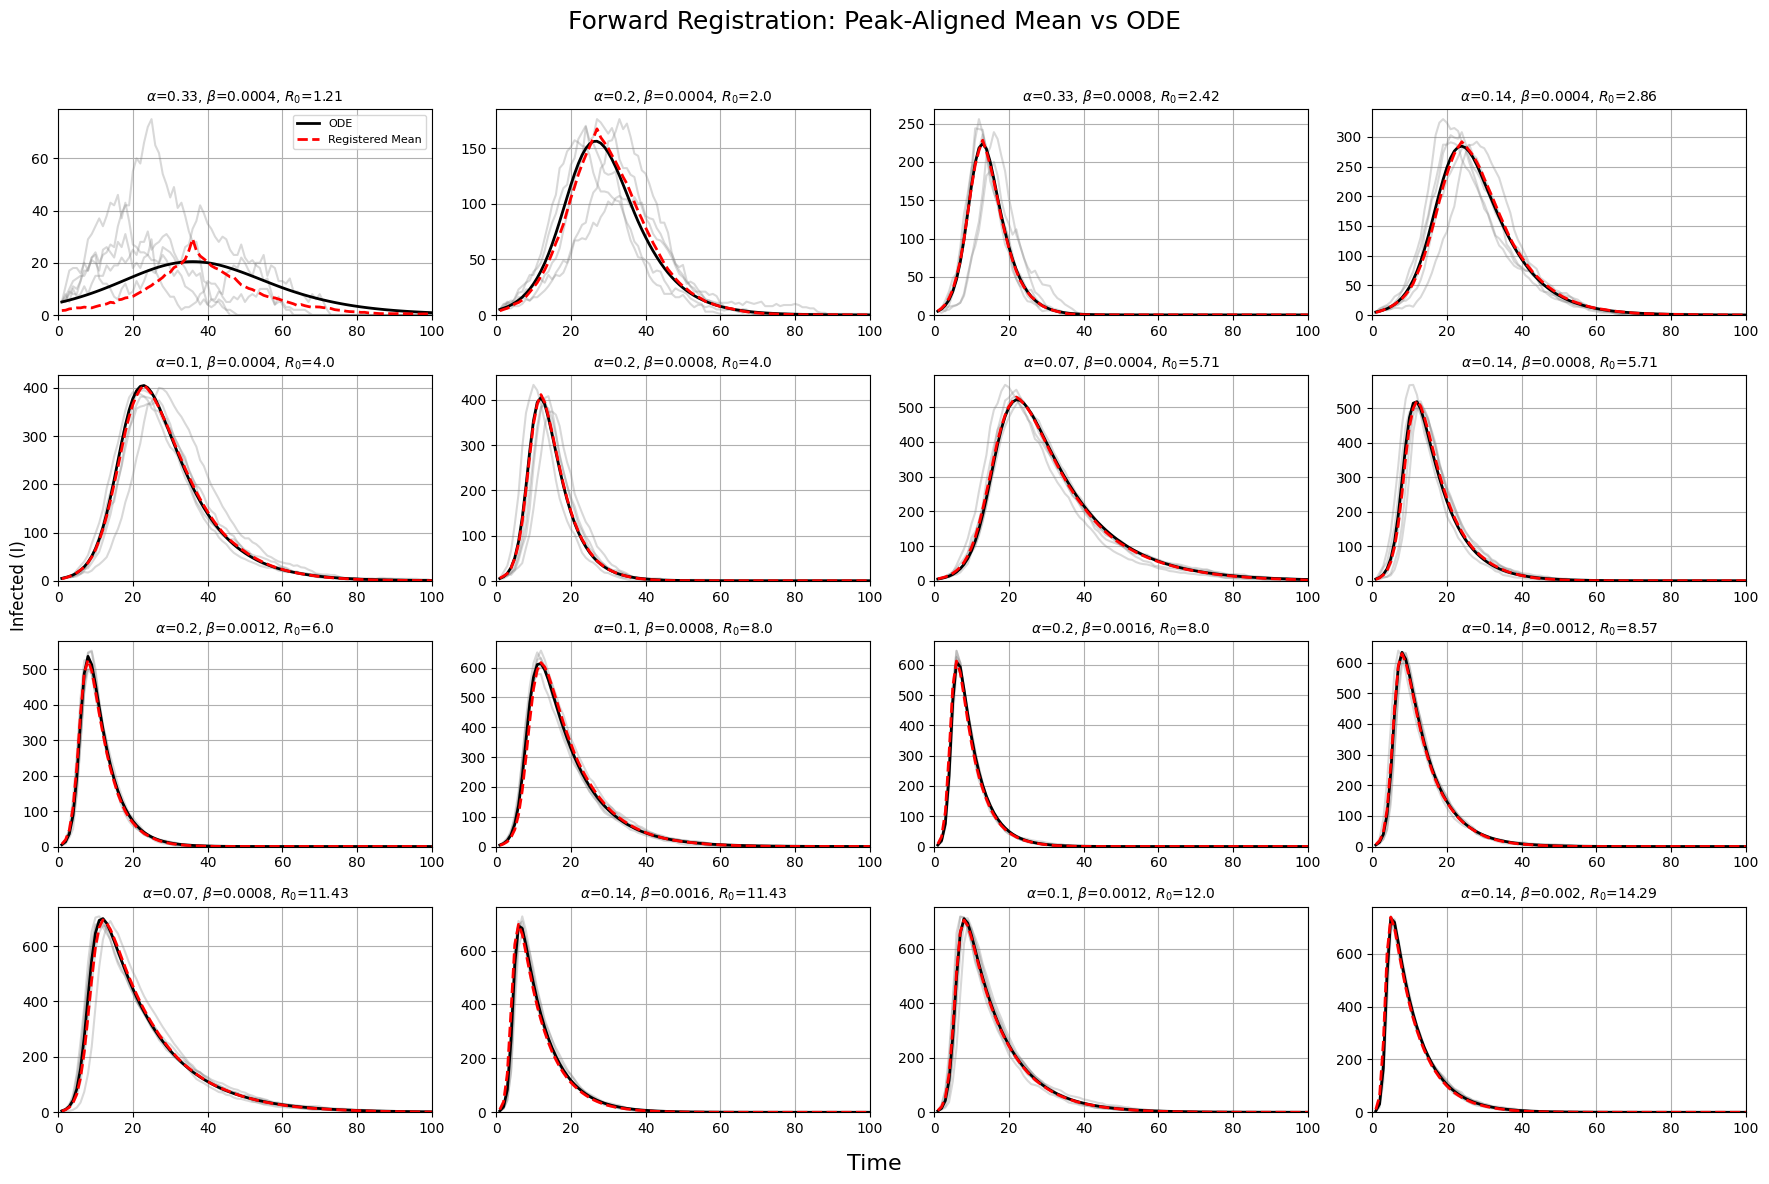

In [12]:
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import numpy as np

# Prep 4x4 plot
num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))
fig, ax = plt.subplots(num_rows, num_cols, figsize=(18, 12))
ax = ax.flatten()

# Sort by R0
sorted_params = params_df.sort_values("R0").reset_index(drop=True)
t_grid = t_eval

for idx, row in sorted_params.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    par = (alpha, beta)
    file = param_to_file.get(par)

    if file is None or not os.path.exists(file):
        ax[idx].text(0.5, 0.5, "Missing file", ha="center", va="center", transform=ax[idx].transAxes)
        continue

    # Solve ODE
    sol = SolveModel(par, tspan, init_cond, t_eval)
    I_ode = sol.y[1]
    peak_time_ode = t_eval[np.argmax(I_ode)]

    # Load CTMC
    df = pd.read_csv(file)
    traj_ids = df["trajectory"].unique()[:50]
    aligned_curves = []
    raw_curves = []

    for traj_id in traj_ids:
        df_traj = df[df["trajectory"] == traj_id]
        t_ctmc = df_traj["time"].values
        I_ctmc = df_traj["I"].values

        interp_func = interp1d(t_ctmc, I_ctmc, bounds_error=False, fill_value=0.0)
        I_interp = interp_func(t_grid)
        raw_curves.append(I_interp)

        # Align peak
        peak_time_ctmc = t_grid[np.argmax(I_interp)]
        shift = peak_time_ode - peak_time_ctmc
        shifted_time = t_grid + shift
        shifted_func = interp1d(shifted_time, I_interp, bounds_error=False, fill_value=0.0)
        I_aligned = shifted_func(t_grid)
        aligned_curves.append(I_aligned)

    # Plot raw CTMCs (optional: only a few)
    for c in raw_curves[:5]:
        ax[idx].plot(t_grid, c, color="gray", alpha=0.3)

    # Plot ODE
    ax[idx].plot(t_grid, I_ode, color="black", linewidth=2, label="ODE")

    # Plot mean registered curve
    if aligned_curves:
        reg_mean = np.mean(aligned_curves, axis=0)
        ax[idx].plot(t_grid, reg_mean, color="red", linestyle="--", linewidth=2, label="Registered Mean")

    ax[idx].set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0}", fontsize=10)
    ax[idx].set_xlim([0, t_final])
    ax[idx].set_ylim(bottom=0)
    ax[idx].grid(True)

    if idx == 0:
        ax[idx].legend(fontsize=8)

# Clean unused axes
for j in range(idx + 1, len(ax)):
    fig.delaxes(ax[j])

fig.suptitle("Forward Registration: Peak-Aligned Mean vs ODE", fontsize=18)
fig.supxlabel("Time", fontsize=16)
fig.supylabel("Infected (I)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [13]:
combo_index = 1
row = params_df.iloc[combo_index]
alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
par = (alpha, beta)
print(R0)

2.0


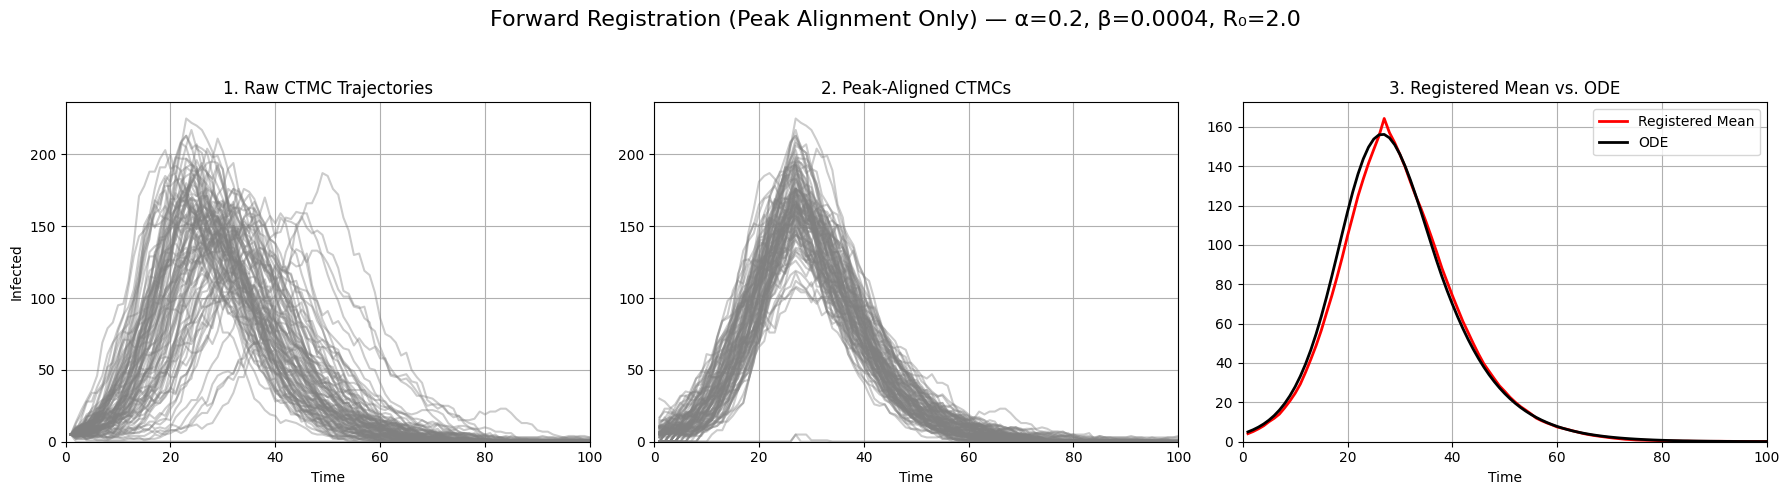

In [14]:
# Choose parameter set
combo_index = 1
row = params_df.iloc[combo_index]
alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
par = (alpha, beta)
file = param_to_file.get(par)

# Solve ODE
sol = SolveModel(par, tspan, init_cond, t_eval)
I_ode = sol.y[1]
peak_time_ode = t_eval[np.argmax(I_ode)]

# Load CTMC
df = pd.read_csv(file)
traj_ids = df["trajectory"].unique()[:100]

raw_ctmc = []
aligned_ctmc = []

for traj_id in traj_ids:
    df_traj = df[df["trajectory"] == traj_id]
    t_ctmc = df_traj["time"].values
    I_ctmc = df_traj["I"].values
    interp_func = interp1d(t_ctmc, I_ctmc, bounds_error=False, fill_value=0.0)
    I_interp = interp_func(t_eval)
    raw_ctmc.append(I_interp)

    peak_time_ctmc = t_eval[np.argmax(I_interp)]
    shift = peak_time_ode - peak_time_ctmc
    shifted_time = t_eval + shift
    shifted_func = interp1d(shifted_time, I_interp, bounds_error=False, fill_value=0.0)
    I_shifted = shifted_func(t_eval)
    aligned_ctmc.append(I_shifted)

# Compute registered mean
registered_mean = np.mean(aligned_ctmc, axis=0)

# Plot 1x3 layout
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 1. Raw CTMC
for curve in raw_ctmc:
    axs[0].plot(t_eval, curve, color="gray", alpha=0.4)
axs[0].set_title("1. Raw CTMC Trajectories")
axs[0].set_xlabel("Time")
axs[0].set_ylabel("Infected")

# 2. Peak-Aligned CTMCs
for curve in aligned_ctmc:
    axs[1].plot(t_eval, curve, color="gray", alpha=0.4)
axs[1].set_title("2. Peak-Aligned CTMCs")
axs[1].set_xlabel("Time")

# 3. Mean Registered vs ODE
axs[2].plot(t_eval, registered_mean, label="Registered Mean", color="red", linewidth=2)
axs[2].plot(t_eval, I_ode, label="ODE", color="black", linewidth=2)
axs[2].set_title("3. Registered Mean vs. ODE")
axs[2].legend()
axs[2].set_xlabel("Time")

# Formatting
for ax in axs:
    ax.set_xlim([0, t_final])
    ax.set_ylim(bottom=0)
    ax.grid(True)

fig.suptitle(f"Forward Registration (Peak Alignment Only) — α={alpha}, β={beta}, R₀={R0}", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


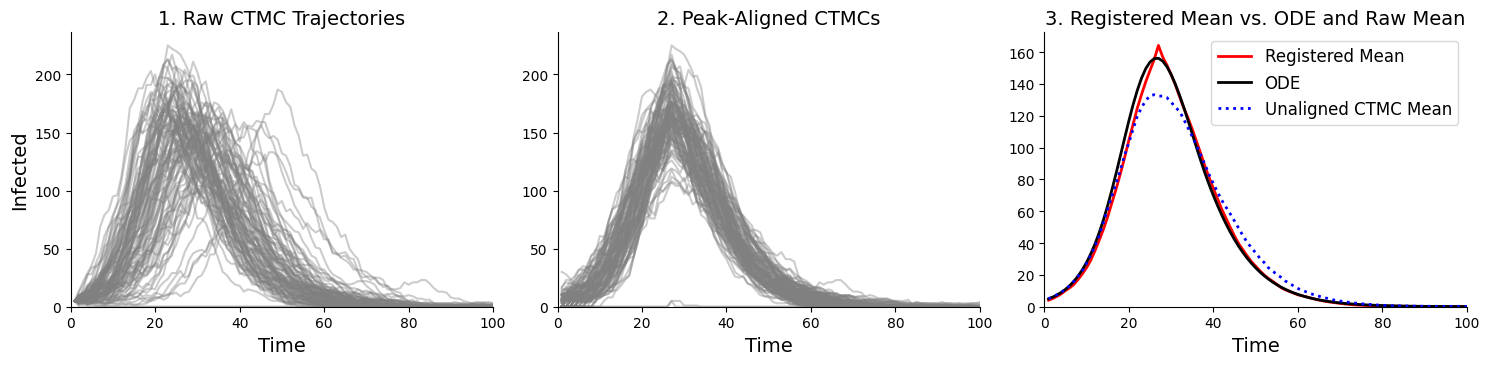

In [15]:
# Plot 1x3 layout
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# 1. Raw CTMC
for curve in raw_ctmc:
    axs[0].plot(t_eval, curve, color="gray", alpha=0.4)
axs[0].set_title("1. Raw CTMC Trajectories", fontsize = 14)
axs[0].set_xlabel("Time",fontsize=14)
axs[0].set_ylabel("Infected",fontsize=14)

# 2. Peak-Aligned CTMCs
for curve in aligned_ctmc:
    axs[1].plot(t_eval, curve, color="gray", alpha=0.4)
axs[1].set_title("2. Peak-Aligned CTMCs", fontsize = 14)
axs[1].set_xlabel("Time",fontsize=14)

# 3. Mean Registered vs ODE and Raw CTMC Mean
raw_mean = np.mean(raw_ctmc, axis=0)

axs[2].plot(t_eval, registered_mean, label="Registered Mean", color="red", linewidth=2)
axs[2].plot(t_eval, I_ode, label="ODE", color="black", linewidth=2)
axs[2].plot(t_eval, raw_mean, label="Unaligned CTMC Mean", color="blue", linestyle=":", linewidth=2)
axs[2].set_title("3. Registered Mean vs. ODE and Raw Mean", fontsize = 14)
axs[2].legend(fontsize = 12)
axs[2].set_xlabel("Time",fontsize=14)

# Formatting
for ax in axs:
    ax.set_xlim([0, t_final])
    ax.set_ylim(bottom=0)
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

#fig.suptitle(f"Forward Registration (Peak Alignment Only) — α={alpha}, β={beta}, R₀={R0}", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

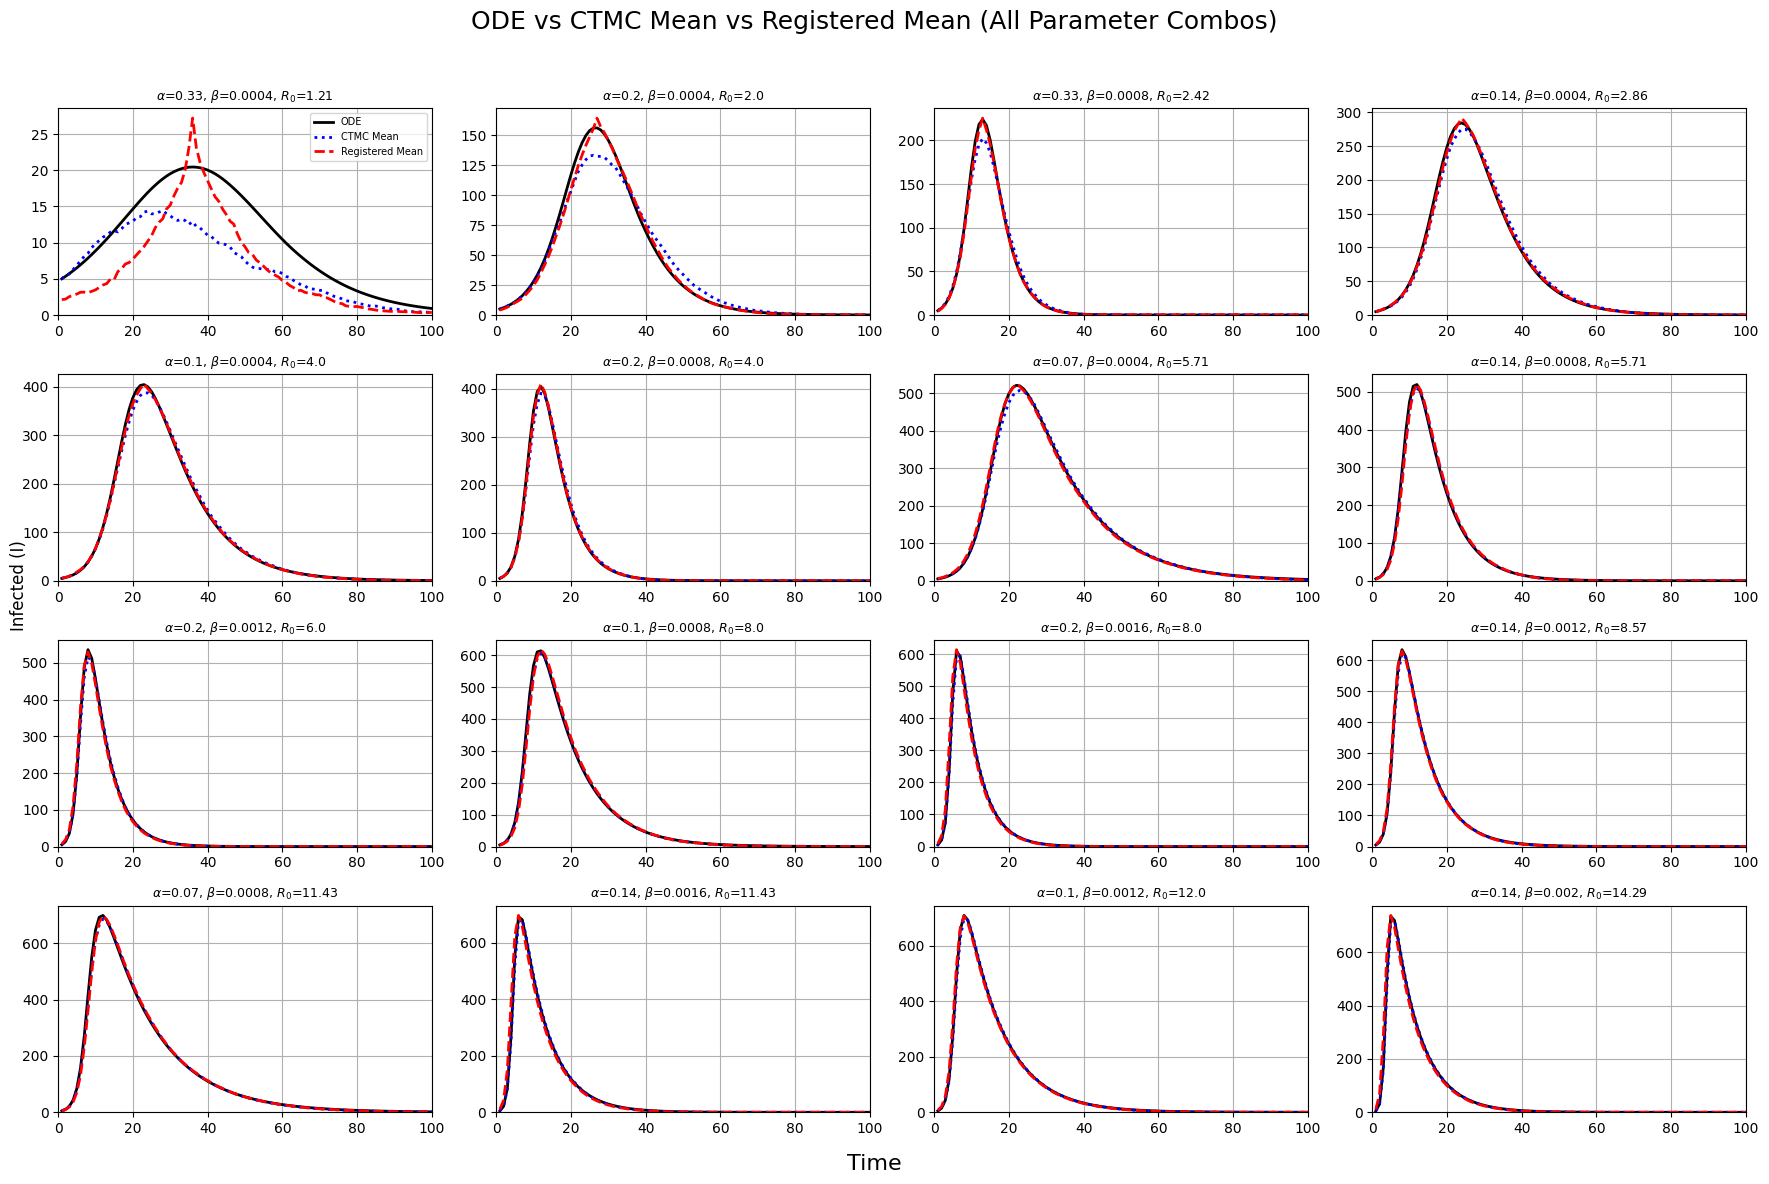

In [16]:
fig, ax = plt.subplots(4, 4, figsize=(18, 12))
ax = ax.flatten()

sorted_params = params_df.sort_values("R0").reset_index(drop=True)
t_grid = t_eval

for idx, row in sorted_params.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    par = (alpha, beta)
    file = param_to_file.get(par)

    if file is None or not os.path.exists(file):
        ax[idx].text(0.5, 0.5, "Missing file", ha="center", va="center", transform=ax[idx].transAxes)
        continue

    # Solve ODE
    sol = SolveModel(par, tspan, init_cond, t_eval)
    I_ode = sol.y[1]
    peak_time_ode = t_grid[np.argmax(I_ode)]

    # Load CTMC
    df = pd.read_csv(file)
    traj_ids = df["trajectory"].unique()[:100]
    raw_ctmc = []
    aligned_ctmc = []

    for traj_id in traj_ids:
        df_traj = df[df["trajectory"] == traj_id]
        t_ctmc = df_traj["time"].values
        I_ctmc = df_traj["I"].values
        interp_func = interp1d(t_ctmc, I_ctmc, bounds_error=False, fill_value=0.0)
        I_interp = interp_func(t_grid)
        raw_ctmc.append(I_interp)

        peak_time_ctmc = t_grid[np.argmax(I_interp)]
        shift = peak_time_ode - peak_time_ctmc
        shifted_time = t_grid + shift
        shifted_func = interp1d(shifted_time, I_interp, bounds_error=False, fill_value=0.0)
        I_shifted = shifted_func(t_grid)
        aligned_ctmc.append(I_shifted)

    # Compute means
    raw_mean = np.mean(raw_ctmc, axis=0)
    reg_mean = np.mean(aligned_ctmc, axis=0)

    # Plot all
    ax[idx].plot(t_grid, I_ode, color="black", linewidth=2, label="ODE")
    ax[idx].plot(t_grid, raw_mean, color="blue", linestyle=":", linewidth=2, label="CTMC Mean")
    ax[idx].plot(t_grid, reg_mean, color="red", linestyle="--", linewidth=2, label="Registered Mean")

    ax[idx].set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0}", fontsize=9)
    ax[idx].set_xlim([0, t_final])
    ax[idx].set_ylim(bottom=0)
    ax[idx].grid(True)

    if idx == 0:
        ax[idx].legend(fontsize=7)

# Hide any unused axes
for j in range(len(sorted_params), len(ax)):
    fig.delaxes(ax[j])

fig.suptitle("ODE vs CTMC Mean vs Registered Mean (All Parameter Combos)", fontsize=18)
fig.supxlabel("Time", fontsize=16)
fig.supylabel("Infected (I)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
